## Module 3: Computational Drug Discovery Project Template

Complete the sections below as a team. Remove the word “Template” only if it appears in the final notebook title.

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 
Provide a brief (<200 word) background of obesity, available treatments, and especially why improved treatments are needed. Your answers may include for example: 
Prevalence & incidence, Symptoms, Diagnosis, Standard of care treatments (& reimbursement), Disease progression & prognosis, Biological mechanisms (anatomy, organ physiology, cell & molecular physiology), Clinical Trials/next-gen therapies.

Please provide citations and/or hyperlinks to where you obtained information (including AI) for each of the bullet points.

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

The program used to model cavalitide and GLP1 binding uses two methods to determine the Kd. A brute force and steepest decent optimization using python's curvefit were both used and yielded similar results. Below shows the setup of parameters for the program, a function for calculating the active fraction, and loading data:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17 # L1, GLP1
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] cavalitide

# Load the data
data = np.loadtxt(r"Module 3\BME2315_Module3\cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

Below is the code used for the brute force method and python curve fit:

In [ ]:
# Approach 1: Brute force optimization of Kd2: try many candidate values in a for loop
Kd2_candidates = np.logspace(-3, 2, 100) # [nM] # checks 100 values between 10^-3 and 10^2 for minimized error
SSE_brute = np.inf
for Kd2_try in Kd2_candidates:
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2)
    if SSE < SSE_brute:
        # stores square of errors and kd2 value if it is lower than the previous minimum
        SSE_brute = SSE 
        Kd2_brute = Kd2_try
print(f"Brute-force Kd2 = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})")

# Approach 2: Python curvefit of Kd2: related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})")

The predictions are plotted against the data points below:

In [ ]:
plt.figure()

plt.semilogx(L2_loaded, Fact_loaded, "o", c="blue",
             label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2,
             label=f"brute-force (Kd2 = {Kd2_brute:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
             label=f"curvefit (Kd2 = {Kd2_fit:.3f} nM)")

plt.ylim(-0.1, 1.1)
plt.xlabel("[cavalitide] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by cavalitide with GLP1 present")
plt.legend(loc="upper left")
plt.show()

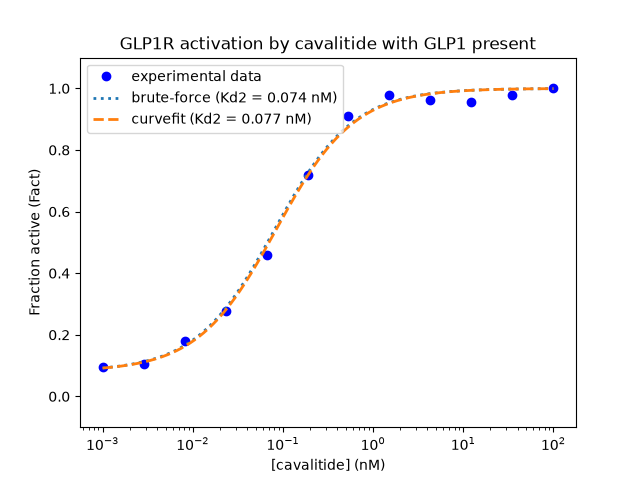

The prediction gives a Kd2 value around the range from 0.074-0.077 nM. This is far lower then the semaglutide Kd2 value of 0.38 nM. This means that cavalitide binds to the GLP1 receptor more tightly than semaglutide, and it takes less of an increase in concentration of cavalitide to increase the fraction of active receptors. This can be advantageous as its increased potency may mean a weaker dose is required to promote fat loss. Additionally, it means its effects can last for a more extended period of time. However, it is important to also consider the other effects this tight binding may have on the body, and other aspects of the drug before it can be determined as a better alternative to semaglutide.

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*